In [1]:
from pathlib import Path

# Point to the research project copy, where T2 results were saved
PROJECT_ROOT = Path(
    "/Users/laasyavavilapalli/Downloads/research_agentic-table-qa/"
    "anacodic-agentic-cookbook"
)

# Confirm that the expected project directory exists
assert PROJECT_ROOT.is_dir(), f"Project directory not found: {PROJECT_ROOT}"

# Inspect experiment files without changing anything
EXPERIMENTS_DIR = PROJECT_ROOT / "02-experiments"

for path in sorted(EXPERIMENTS_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in {".py", ".ipynb", ".csv"}:
        print(path.relative_to(PROJECT_ROOT))

02-experiments/amaresh-eval-harness/01-run-one-question.ipynb
02-experiments/amaresh-eval-harness/extraction/metadata_fidelity.py
02-experiments/amaresh-eval-harness/extraction/metrics.py
02-experiments/amaresh-eval-harness/extraction/run_extraction_benchmark.py
02-experiments/amaresh-eval-harness/provider/charts.py
02-experiments/amaresh-eval-harness/provider/export_public_summary.py
02-experiments/amaresh-eval-harness/provider/graph_store.py
02-experiments/amaresh-eval-harness/provider/local_pipeline.py
02-experiments/amaresh-eval-harness/provider/local_queries.py
02-experiments/amaresh-eval-harness/provider/local_retrieval.py
02-experiments/amaresh-eval-harness/provider/ollama_embed.py
02-experiments/amaresh-eval-harness/provider/reembed_corpus.py
02-experiments/amaresh-eval-harness/provider/results/local_pilot_trials.csv
02-experiments/amaresh-eval-harness/provider/run_local_pilot.py
02-experiments/amaresh-eval-harness/provider/run_single_benchmark.py
02-experiments/amaresh-eval-ha

In [2]:
# Locate the existing analysis script
ANALYSIS_SCRIPT = (
    PROJECT_ROOT
    / "02-experiments"
    / "laasya-table-eval"
    / "analyze_results.py"
)

# Verify that the script exists
assert ANALYSIS_SCRIPT.is_file(), f"Script not found: {ANALYSIS_SCRIPT}"

# Display the complete script so we can understand its current analysis
print(ANALYSIS_SCRIPT.read_text())

"""Analyze table-QA result CSVs: accuracy by reasoning type + ablation delta + a figure.

Reads every *.csv in results-input/ (columns: question, gold, pred, correct,
reasoning_type, model, config). Prints per-config accuracy and, if both a
'naive' and a 'table_aware' config are present, the ablation delta. Saves a bar
chart to results/accuracy_by_type.png. No model calls — pure analysis of outputs.
"""
import glob
import os

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

HERE = os.path.dirname(__file__)
IN = os.path.join(HERE, "results-input")
OUT = os.path.join(HERE, "results")


def load() -> pd.DataFrame:
    files = glob.glob(os.path.join(IN, "*.csv"))
    if not files:
        raise SystemExit(
            f"no CSVs found in {IN}. Put a result file there first "
            f"(a real sample is provided — see FIRST_TASK.md)."
        )
    return pd.concat([pd.read_csv(f) for f in files], ignore_index=True)


def main():
    os.makedir

In [3]:
# Locate the existing T3 notebook
import json

NOTEBOOK_PATH = (
    PROJECT_ROOT
    / "02-experiments"
    / "laasya-table-eval"
    / "notebooks"
    / "02-accuracy-table-figures.ipynb"
)

# Read the notebook without modifying it
with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

# Print each cell so we can inspect the existing workflow
for i, cell in enumerate(notebook["cells"]):
    print(f"\n--- CELL {i + 1} ({cell['cell_type']}) ---")
    print("".join(cell["source"]))


--- CELL 1 (code) ---
from pathlib import Path

# Point to the research project copy, where T2 results were saved
PROJECT_ROOT = Path(
    "/Users/laasyavavilapalli/Downloads/research_agentic-table-qa/"
    "anacodic-agentic-cookbook"
)

# Confirm that the expected project directory exists
assert PROJECT_ROOT.is_dir(), f"Project directory not found: {PROJECT_ROOT}"

# Inspect experiment files without changing anything
EXPERIMENTS_DIR = PROJECT_ROOT / "02-experiments"

for path in sorted(EXPERIMENTS_DIR.rglob("*")):
    if path.is_file() and path.suffix.lower() in {".py", ".ipynb", ".csv"}:
        print(path.relative_to(PROJECT_ROOT))

--- CELL 2 (code) ---
# Locate the existing analysis script
ANALYSIS_SCRIPT = (
    PROJECT_ROOT
    / "02-experiments"
    / "laasya-table-eval"
    / "analyze_results.py"
)

# Verify that the script exists
assert ANALYSIS_SCRIPT.is_file(), f"Script not found: {ANALYSIS_SCRIPT}"

# Display the complete script so we can understand its current analysis
p

In [4]:
import pandas as pd

# Check the table-evaluation input directory and Rashan's experiment outputs
CSV_DIRECTORIES = [
    PROJECT_ROOT / "02-experiments" / "laasya-table-eval" / "results-input",
    PROJECT_ROOT / "02-experiments" / "rashan-table-agent" / "results",
]

for directory in CSV_DIRECTORIES:
    print(f"\n{'=' * 80}")
    print(f"DIRECTORY: {directory}")
    print(f"EXISTS: {directory.is_dir()}")

    if not directory.is_dir():
        continue

    csv_files = sorted(directory.glob("*.csv"))

    for csv_path in csv_files:
        print(f"\n--- {csv_path.name} ---")

        # Read the file to inspect its structure
        data = pd.read_csv(csv_path)

        print(f"Rows: {len(data)}")
        print(f"Columns: {data.columns.tolist()}")
        print(data.head(3).to_string(index=False))


DIRECTORY: /Users/laasyavavilapalli/Downloads/research_agentic-table-qa/anacodic-agentic-cookbook/02-experiments/laasya-table-eval/results-input
EXISTS: True

--- chatgpt_reference_sample.csv ---
Rows: 40
Columns: ['question', 'gold', 'pred', 'correct', 'reasoning_type', 'model', 'config']
                                                                                                               question           gold           pred  correct reasoning_type             model            config
What is the total length of the sequence formed by concatenating the forward and reverse primers for Promoter & Exon 1? 48 nucleotides 60 nucleotides        0     Arithmetic chatgpt-reference chatgpt_reference
                                   What is the difference in length between the forward and reverse primers for Exon 2?  3 nucleotides 20 nucleotides        0     Arithmetic chatgpt-reference chatgpt_reference
  What is the total length of the sequence formed by concatenating the forward

In [5]:
import pandas as pd

# Identify the three files that appear to share the primer-question dataset
COMPARISON_FILES = {
    "chatgpt_reference": (
        PROJECT_ROOT
        / "02-experiments/laasya-table-eval/results-input/chatgpt_reference_sample.csv"
    ),
    "naive": (
        PROJECT_ROOT
        / "02-experiments/rashan-table-agent/results/naive.csv"
    ),
    "table_aware": (
        PROJECT_ROOT
        / "02-experiments/rashan-table-agent/results/table_aware.csv"
    ),
}

# Load each file for comparison
comparison_data = {
    name: pd.read_csv(path)
    for name, path in COMPARISON_FILES.items()
}

# Check question counts, duplicates, and question-set agreement
for name, data in comparison_data.items():
    print(
        f"{name}: {len(data)} rows | "
        f"{data['question'].nunique()} unique questions"
    )

reference_questions = set(
    comparison_data["chatgpt_reference"]["question"]
)

for name, data in comparison_data.items():
    questions = set(data["question"])

    print(f"\n{name}:")
    print(f"  Missing reference questions: {len(reference_questions - questions)}")
    print(f"  Additional questions: {len(questions - reference_questions)}")

# Check whether reasoning-type labels agree across the three files
for name, data in comparison_data.items():
    print(f"\n{name} reasoning types:")
    print(data["reasoning_type"].value_counts(dropna=False).to_string())

chatgpt_reference: 40 rows | 39 unique questions
naive: 40 rows | 39 unique questions
table_aware: 40 rows | 39 unique questions

chatgpt_reference:
  Missing reference questions: 0
  Additional questions: 0

naive:
  Missing reference questions: 0
  Additional questions: 0

table_aware:
  Missing reference questions: 0
  Additional questions: 0

chatgpt_reference reasoning types:
reasoning_type
Arithmetic                  12
Cell Selection               9
Counting                     4
Percentage calculation       4
Calculation                  3
Total count                  2
Identification               1
Percentage Calculation       1
Count                        1
Most Common                  1
Summation                    1
Max Value Identification     1

naive reasoning types:
reasoning_type
Arithmetic                  12
Cell Selection               9
Counting                     4
Percentage calculation       4
Calculation                  3
Total count                  2
Iden

In [6]:
# Find questions that occur more than once in each dataset
for name, data in comparison_data.items():
    duplicated = data[
        data["question"].duplicated(keep=False)
    ]

    print(f"\n--- {name}: duplicated questions ---")

    # Display only the relevant fields for the duplicate rows
    print(
        duplicated[
            ["question", "gold", "pred", "correct", "reasoning_type"]
        ].to_string(index=False)
    )

# Verify that all three files have the same row order
print("\n--- Row-order consistency ---")

reference_order = comparison_data["chatgpt_reference"]["question"].tolist()

for name, data in comparison_data.items():
    same_order = data["question"].tolist() == reference_order
    print(f"{name}: same question order = {same_order}")


--- chatgpt_reference: duplicated questions ---
                                                                                                 question      gold      pred  correct reasoning_type
What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?  4 DONORS 15 donors        0    Total count
What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories? 11 donors 11 donors        1      Summation

--- naive: duplicated questions ---
                                                                                                 question      gold      pred  correct reasoning_type
What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?  4 DONORS 15 donors        0    Total count
What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories? 11 donors 11 donors        1      Summation

--- table_awa

In [7]:
# Inspect the duplicated question with all available columns
duplicate_question = (
    "What is the total number of donors contributing oocytes "
    "with premeiotic aneuploidy across all categories?"
)

for name, data in comparison_data.items():
    print(f"\n--- {name} ---")

    # Display both records, including their original row indexes
    duplicates = data[
        data["question"] == duplicate_question
    ]

    print(duplicates.to_string())


--- chatgpt_reference ---
                                                                                                     question       gold       pred  correct reasoning_type              model             config
17  What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?   4 DONORS  15 donors        0    Total count  chatgpt-reference  chatgpt_reference
27  What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?  11 donors  11 donors        1      Summation  chatgpt-reference  chatgpt_reference

--- naive ---
                                                                                                     question       gold       pred  correct reasoning_type                    model config  run
17  What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?   4 DONORS  15 donors        0    Total count  groq:openai/gpt-oss-20b  n

In [8]:
# Search project text and source files for the exact duplicated question
search_phrase = (
    "What is the total number of donors contributing oocytes "
    "with premeiotic aneuploidy across all categories?"
)

search_extensions = {".py", ".csv", ".md", ".json", ".txt"}

for path in PROJECT_ROOT.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in search_extensions:
        continue

    # Skip generated environments and dependency directories
    if any(part.startswith(".") or part in {
        "__pycache__", "node_modules", ".venv"
    } for part in path.parts):
        continue

    try:
        content = path.read_text(encoding="utf-8")
    except (UnicodeDecodeError, OSError):
        continue

    if search_phrase in content:
        print(f"\nFOUND IN: {path.relative_to(PROJECT_ROOT)}")

        # Show matching lines with their line numbers
        for line_number, line in enumerate(content.splitlines(), start=1):
            if search_phrase in line:
                print(f"  Line {line_number}: {line.strip()}")


FOUND IN: 02-experiments/rashan-table-agent/results/table_aware.csv
  Line 19: What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?,4 DONORS,15 donors,0,Total count,groq:openai/gpt-oss-20b,table_aware,3
  Line 29: What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?,11 donors,11 donors,1,Summation,groq:openai/gpt-oss-20b,table_aware,3

FOUND IN: 02-experiments/rashan-table-agent/results/naive.csv
  Line 19: What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?,4 DONORS,15 donors,0,Total count,groq:openai/gpt-oss-20b,naive,3
  Line 29: What is the total number of donors contributing oocytes with premeiotic aneuploidy across all categories?,11 donors,11 donors,1,Summation,groq:openai/gpt-oss-20b,naive,3

FOUND IN: 02-experiments/laasya-table-eval/results-input/chatgpt_reference_sample.csv
  Line 19: What is the total number of dono

In [9]:
def load_comparison_data():
    """
    Load the three matching 40-question evaluation datasets.

    Explicit file paths prevent unrelated experiment CSVs from
    accidentally entering the comparison.
    """

    # Map each configuration to its original result CSV
    file_paths = {
        "chatgpt_reference": (
            PROJECT_ROOT
            / "02-experiments/laasya-table-eval/results-input"
            / "chatgpt_reference_sample.csv"
        ),
        "naive": (
            PROJECT_ROOT
            / "02-experiments/rashan-table-agent/results"
            / "naive.csv"
        ),
        "table_aware": (
            PROJECT_ROOT
            / "02-experiments/rashan-table-agent/results"
            / "table_aware.csv"
        ),
    }

    # Define the columns required for accuracy analysis
    required_columns = {
        "question",
        "gold",
        "pred",
        "correct",
        "reasoning_type",
        "config",
    }

    # Load and validate each selected dataset
    datasets = {}

    for config_name, file_path in file_paths.items():

        if not file_path.is_file():
            raise FileNotFoundError(
                f"Missing result file: {file_path}"
            )

        data = pd.read_csv(file_path)

        missing_columns = required_columns - set(data.columns)

        if missing_columns:
            raise ValueError(
                f"{config_name} is missing columns: {missing_columns}"
            )

        datasets[config_name] = data

    return datasets

In [10]:
# Load the three selected evaluation datasets
comparison_data = load_comparison_data()

# Inspect the loaded datasets
for config_name, data in comparison_data.items():
    print(f"\n--- {config_name} ---")
    print(f"Rows: {len(data)}")
    print(f"Configuration labels: {data['config'].unique().tolist()}")
    print(f"Correctness values: {sorted(data['correct'].dropna().unique())}")
    print(f"Reasoning types: {data['reasoning_type'].nunique()}")


--- chatgpt_reference ---
Rows: 40
Configuration labels: ['chatgpt_reference']
Correctness values: [np.int64(0), np.int64(1)]
Reasoning types: 12

--- naive ---
Rows: 40
Configuration labels: ['naive']
Correctness values: [np.int64(0), np.int64(1)]
Reasoning types: 12

--- table_aware ---
Rows: 40
Configuration labels: ['table_aware']
Correctness values: [np.int64(0), np.int64(1)]
Reasoning types: 12


In [11]:
def calculate_overall_accuracy(datasets):
    """
    Calculate the number and percentage of correct answers
    for each evaluation configuration.
    """

    results = []

    for config_name, data in datasets.items():

        # Count correct answers and total evaluated questions
        correct_count = data["correct"].sum()
        total_count = len(data)

        # Calculate accuracy as a percentage
        accuracy = correct_count / total_count * 100

        results.append({
            "config": config_name,
            "correct": int(correct_count),
            "total": total_count,
            "accuracy_percent": round(accuracy, 2),
        })

    return pd.DataFrame(results)

In [12]:
# Calculate overall accuracy for each configuration
overall_accuracy = calculate_overall_accuracy(comparison_data)

# Display the results
print("Overall accuracy by configuration:")
display(overall_accuracy)

Overall accuracy by configuration:


,config,correct,total,accuracy_percent
0,chatgpt_reference,26,40,65.0
1,naive,22,40,55.0
2,table_aware,23,40,57.5


In [13]:
def calculate_accuracy_by_type(datasets):
    """
    Calculate correct-answer counts and accuracy percentages
    for each configuration and reasoning type.

    Original reasoning-type labels are preserved.
    """

    results = []

    for config_name, data in datasets.items():

        # Group questions by their original reasoning-type labels
        grouped = data.groupby("reasoning_type")["correct"].agg(
            correct="sum",
            total="count"
        )

        # Calculate accuracy within each reasoning type
        grouped["accuracy_percent"] = (
            grouped["correct"] / grouped["total"] * 100
        ).round(2)

        # Add the configuration name to each result
        grouped["config"] = config_name

        results.append(grouped.reset_index())

    return pd.concat(results, ignore_index=True)

In [14]:
# Calculate accuracy grouped by reasoning type
accuracy_by_type = calculate_accuracy_by_type(comparison_data)

# Display results sorted by reasoning type and configuration
accuracy_by_type = accuracy_by_type.sort_values(
    ["reasoning_type", "config"]
).reset_index(drop=True)

display(accuracy_by_type)

,reasoning_type,correct,total,accuracy_percent,config
0,Arithmetic,3,12,25.00,chatgpt_reference
1,Arithmetic,3,12,25.00,naive
2,Arithmetic,4,12,33.33,table_aware
3,Calculation,2,3,66.67,chatgpt_reference
4,Calculation,0,3,0.00,naive
5,Calculation,0,3,0.00,table_aware
6,Cell Selection,9,9,100.00,chatgpt_reference
7,Cell Selection,8,9,88.89,naive
8,Cell Selection,8,9,88.89,table_aware
9,Count,0,1,0.00,chatgpt_reference


In [15]:
def create_reasoning_comparison_table(accuracy_data):
    """
    Create a side-by-side table of accuracy percentages
    for each reasoning type and evaluation configuration.
    """

    # Reshape the results so each configuration gets its own column
    comparison = accuracy_data.pivot(
        index="reasoning_type",
        columns="config",
        values="accuracy_percent"
    )

    # Give the table a clean column-axis name
    comparison.columns.name = None

    # Return the comparison table
    return comparison.reset_index()

In [16]:
# Create the side-by-side accuracy comparison
reasoning_comparison = create_reasoning_comparison_table(
    accuracy_by_type
)

# Display the comparison
display(reasoning_comparison)

,reasoning_type,chatgpt_reference,naive,table_aware
0,Arithmetic,25.00,25.00,33.33
1,Calculation,66.67,0.00,0.00
2,Cell Selection,100.00,88.89,88.89
3,Count,0.00,100.00,100.00
4,Counting,75.00,75.00,50.00
5,Identification,100.00,100.00,100.00
6,Max Value Identification,100.00,100.00,100.00
7,Most Common,100.00,0.00,0.00
8,Percentage Calculation,0.00,0.00,0.00
9,Percentage calculation,100.00,75.00,100.00


In [17]:
def calculate_ablation_delta(accuracy_data, overall_data):
    """
    Calculate table-aware minus naive accuracy differences.

    Results are expressed in percentage points.
    Positive values favor table-aware reasoning.
    """

    # Calculate accuracy differences by reasoning type
    type_pivot = accuracy_data.pivot(
        index="reasoning_type",
        columns="config",
        values="accuracy_percent"
    )

    type_delta = (
        type_pivot["table_aware"] - type_pivot["naive"]
    ).rename("delta_percentage_points")

    type_delta = type_delta.reset_index()

    # Calculate the overall accuracy difference
    overall_values = overall_data.set_index("config")[
        "accuracy_percent"
    ]

    overall_delta = (
        overall_values["table_aware"] - overall_values["naive"]
    )

    return type_delta, round(overall_delta, 2)

In [18]:
# Calculate the naive-to-table-aware ablation differences
ablation_by_type, overall_ablation_delta = calculate_ablation_delta(
    accuracy_by_type,
    overall_accuracy
)

# Display the overall accuracy difference
print(
    f"Overall ablation delta: "
    f"{overall_ablation_delta:+.2f} percentage points"
)

# Display the differences by reasoning type
display(ablation_by_type)

Overall ablation delta: +2.50 percentage points


,reasoning_type,delta_percentage_points
0,Arithmetic,8.33
1,Calculation,0.00
2,Cell Selection,0.00
3,Count,0.00
4,Counting,-25.00
5,Identification,0.00
6,Max Value Identification,0.00
7,Most Common,0.00
8,Percentage Calculation,0.00
9,Percentage calculation,25.00


In [22]:
def save_accuracy_figure(reasoning_comparison):
    """
    Create and save a grouped bar chart of accuracy by reasoning type.
    """

    import matplotlib.pyplot as plt

    # Use reasoning types as the chart index
    plot_data = reasoning_comparison.set_index("reasoning_type")

    # Create a wide figure so labels remain readable
    ax = plot_data.plot(
        kind="bar",
        figsize=(14, 6),
        width=0.8
    )

    # Label and format the chart
    ax.set_title("Accuracy by Reasoning Type")
    ax.set_xlabel("Reasoning Type")
    ax.set_ylabel("Accuracy (%)")
    ax.set_ylim(0, 105)
    ax.legend(title="Configuration")

    # Rotate category labels for readability
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

    # Save the figure in the evaluation results directory
    output_path = (
        PROJECT_ROOT
        / "02-experiments/laasya-table-eval/results"
        / "accuracy_by_type2.png"
    )

    output_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(output_path, dpi=150, bbox_inches="tight")

    # Return the saved figure path
    plt.close()

    return output_path

In [23]:
def export_t3_results(
    overall_accuracy,
    accuracy_by_type,
    reasoning_comparison,
    ablation_by_type,
    overall_ablation_delta
):
    """
    Export all T3 accuracy tables and ablation results as CSV files.
    """

    # Define the output directory
    output_dir = (
        PROJECT_ROOT
        / "02-experiments/laasya-table-eval/results"
    )

    # Create the directory if it does not exist
    output_dir.mkdir(parents=True, exist_ok=True)

    # Save overall accuracy results
    overall_accuracy.to_csv(
        output_dir / "overall_accuracy.csv",
        index=False
    )

    # Save accuracy grouped by reasoning type
    accuracy_by_type.to_csv(
        output_dir / "accuracy_by_reasoning_type.csv",
        index=False
    )

    # Save the side-by-side reasoning comparison
    reasoning_comparison.to_csv(
        output_dir / "reasoning_type_comparison.csv",
        index=False
    )

    # Save ablation differences by reasoning type
    ablation_by_type.to_csv(
        output_dir / "ablation_by_reasoning_type.csv",
        index=False
    )

    # Save the overall ablation result
    ablation_summary = pd.DataFrame({
        "comparison": ["table_aware_minus_naive"],
        "delta_percentage_points": [overall_ablation_delta]
    })

    ablation_summary.to_csv(
        output_dir / "ablation_summary.csv",
        index=False
    )

    # Return the output directory for verification
    return output_dir

In [24]:
# Export the T3 accuracy tables
output_dir = export_t3_results(
    overall_accuracy,
    accuracy_by_type,
    reasoning_comparison,
    ablation_by_type,
    overall_ablation_delta
)

# Inspect the files saved in the results directory
expected_files = [
    "overall_accuracy.csv",
    "accuracy_by_reasoning_type.csv",
    "reasoning_type_comparison.csv",
    "ablation_by_reasoning_type.csv",
    "ablation_summary.csv",
]

for filename in expected_files:

    # Confirm that each expected file exists
    file_path = output_dir / filename

    print(
        f"{filename}: "
        f"{'SAVED' if file_path.is_file() else 'MISSING'}"
    )

overall_accuracy.csv: SAVED
accuracy_by_reasoning_type.csv: SAVED
reasoning_type_comparison.csv: SAVED
ablation_by_reasoning_type.csv: SAVED
ablation_summary.csv: SAVED


Figure path: /Users/laasyavavilapalli/Downloads/research_agentic-table-qa/anacodic-agentic-cookbook/02-experiments/laasya-table-eval/results/accuracy_by_type2.png
Figure saved: True


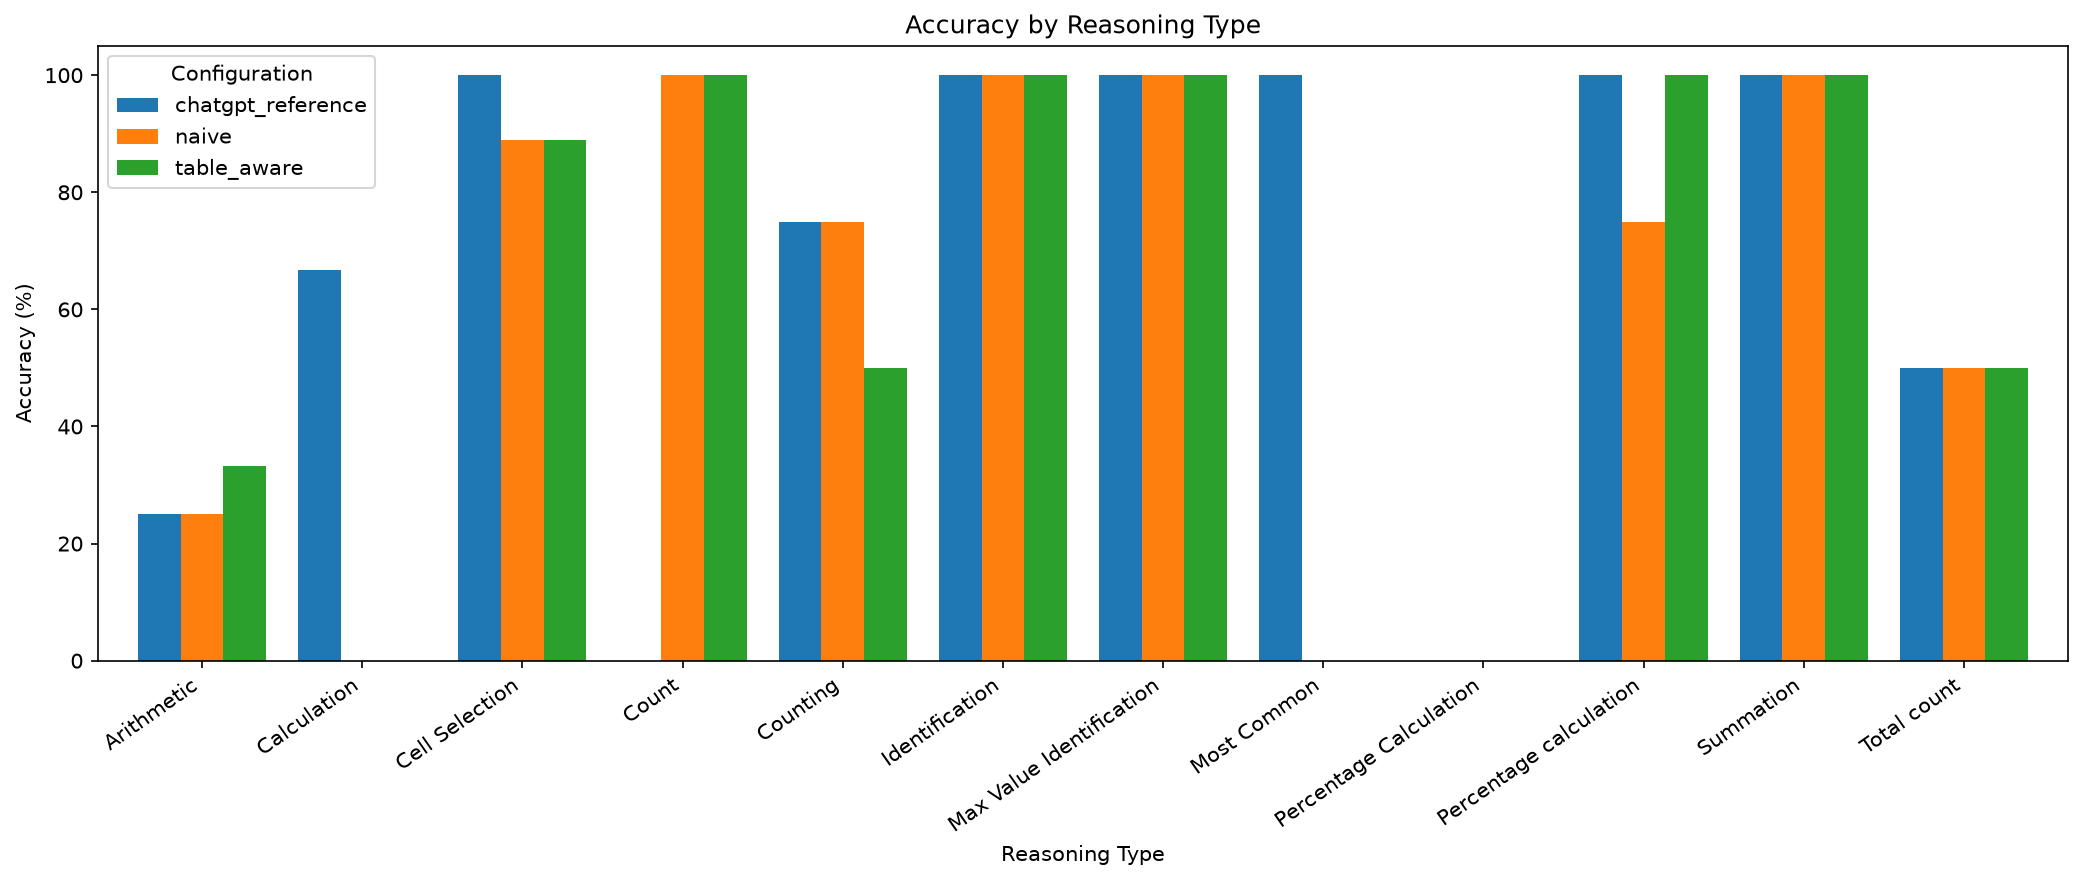

In [25]:
# Generate and save the accuracy comparison figure
figure_path = save_accuracy_figure(reasoning_comparison)

# Confirm that the figure exists
print(f"Figure path: {figure_path}")
print(f"Figure saved: {figure_path.is_file()}")

# Display the figure
from IPython.display import Image, display

display(Image(filename=str(figure_path)))